# Figure S13 — the same region-number sweep for every method

The fully nested procedure of the data-driven model (ranking function, number of regions *k*,
classifier and hyperparameters chosen inside each outer fold on inner-CV scores) is run on every
method's own region set as a *k*-sweep, one complete nested selection per fixed *k*, for both tasks:

| method | region set | *k* grid |
|---|---|---|
| data-driven | 14,221 TSSs × 5 fragmentomic features | 10 … 15,000 (= all) |
| RNA | 792 Zhu et al. expression-selected regions, feature `rcov` | 10 … 792 (= all) |
| ATAC | 504 Ulz et al. TF-level features (each the aggregate over that TF's top-1000 binding sites) | 10 … 504 (= all) |

*k* selects among the unique columns of each set: the pipeline drops columns that are identical across
all samples (e.g. 792 Zhu regions → 781 unique).

Two arms per method. Tuned: per outer fold the *k* with the best inner-CV score, derived from the sweep
(every *k* uses the same seeded inner splits, so this equals a single fully nested run over the whole
*k* grid; checked in the QC section). Fixed: all regions, no selection, classifier chosen per fold; its
counterpart inside the sweep is the *k* = all point.

Figure: (a) BRCA/CRC, (b) pan-cancer: AUROC against the number of regions, mean ± sd over the outer
folds; the last point of each curve uses all regions, and the legend gives the k-tuned and all-regions
AUROCs. `panel_roc` (mean ROC of the k-tuned arms) is not part of the figure.

Source data (this notebook reads nothing else):
- `data/figS13_ksweep_folds.csv` — per (task, method, *k*, fold): winning
  configuration, inner-CV and test AUROC, regions used / available.
- `data/figS13_predictions.csv` — per (task, method, arm, *k*, fold, sample):
  out-of-fold score and the fold's train-derived 95%-specificity threshold.
- `data/figS13_arms.csv` — per (task, method, arm[, *k*]): AUROC summaries,
  modal configuration, *k* votes, provenance.
- `data/figS13_fold_configs.csv` — per fold of the tuned / fixed arms: the
  winning configuration, plus the tuned arm's cross-checks (QC section).

All written by `export/export_figS13.py`. Run this notebook top to bottom from `src/figures/`.

In [1]:
import os

# Data paths are relative to src/figures/; hop there if the kernel started elsewhere
# (e.g. VSCode with jupyter.notebookFileRoot = workspaceFolder).
if not os.path.isdir("data") and os.path.isdir(os.path.join("src", "figures", "data")):
    os.chdir(os.path.join("src", "figures"))

# --- cohort switch ------------------------------------------------------------------
# "no_deep" (default): without the 30 deep-sequenced healthy controls (exporters run with
# COHORT_VARIANT=no_deep, data/no_deep/); "all": the full cohort. Set COHORT here or FIG_COHORT
# in the environment. A file not exported for the variant falls back to the full-cohort file,
# with a notice. Figures go to output/<variant>/.
COHORT = os.environ.get("FIG_COHORT", "no_deep")   # no_deep is the default cohort
assert COHORT in ("all", "no_deep"), COHORT
_DATA = "data" if COHORT == "all" else os.path.join("data", COHORT)
_OUT = "output" if COHORT == "all" else os.path.join("output", COHORT)
os.makedirs(_OUT, exist_ok=True)
_FALLBACKS = set()


def data_path(name):
    """Source-data path for the selected cohort (full-cohort fallback with a notice)."""
    p = os.path.join(_DATA, name)
    if COHORT != "all" and not os.path.exists(p):
        if name not in _FALLBACKS:
            print(f"   [cohort {COHORT}] {name} not exported for this cohort - using the full-cohort file")
            _FALLBACKS.add(name)
        p = os.path.join("data", name)
    return p


def out_path(name):
    """Output path for the selected cohort."""
    return os.path.join(_OUT, name)


print(f"cohort: {COHORT} (source data from {_DATA}/, figures to {_OUT}/)")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import _figstyle as fs
fs.apply()
from matplotlib.lines import Line2D
from scipy.interpolate import interp1d
from scipy.stats import rankdata, wilcoxon
from sklearn.metrics import roc_auc_score, roc_curve, auc

TASK_LABELS = {"brca_crc": "Healthy vs BRCA + CRC", "pancan": "Healthy vs PANCAN"}
METHODS = ["data_driven", "rna", "atac"]
METHOD_LABELS = {"data_driven": "Data-driven", "rna": "RNA", "atac": "ATAC"}
METHOD_COLORS = {"data_driven": "#0173B2", "rna": "#CA3542", "atac": "#ECB22E"}  # as Fig 3
REGION_UNIT = {"data_driven": "TSSs", "rna": "regions", "atac": "TFs"}
NO_FIXED_ARM = {"data_driven"}
ARM_LABELS = {"fixed": "fixed regions (manuscript)", "tuned": "k tuned per fold",
              "ksweep": "sweep"}


cohort: no_deep (source data from data\no_deep/, figures to output\no_deep/)


In [2]:
pred = pd.read_csv(data_path("figS13_predictions.csv"))
arms = pd.read_csv(data_path("figS13_arms.csv"))
folds = pd.read_csv(data_path("figS13_ksweep_folds.csv"))
cfg = pd.read_csv(data_path("figS13_fold_configs.csv"))
TASKS = [t for t in TASK_LABELS if t in set(arms["task"])]
print(f"tasks: {TASKS}")

# The exporter writes whatever runs exist; report missing sweeps or tuned arms so that a
# partial figure is not mistaken for the final one.
INCOMPLETE = False
ABSENT = set()      # (task, method) pairs without an exported run
for task in TASKS:
    for m in METHODS:
        have = set(arms[(arms["task"] == task) & (arms["method"] == m)]["arm"])
        if not have:
            print(f"  {task:<9} {m:<14} ABSENT (no exported run; dropped from this task's panels)")
            ABSENT.add((task, m))
            continue
        want = {"ksweep", "tuned"} | ({"fixed"} if m not in NO_FIXED_ARM else set())
        missing = sorted(want - have)
        ks = sorted(arms[(arms["task"] == task) & (arms["method"] == m)
                         & (arms["arm"] == "ksweep")]["k"].dropna().astype(int))
        status = "complete" if not missing else f"MISSING {missing}"
        if missing:
            INCOMPLETE = True
        print(f"  {task:<9} {m:<14} {status:<28} sweep k = {ks if ks else '-'}")
# a method absent in one task but exported in the other is an intermediate state
for task, m in ABSENT:
    if any((t, m) not in ABSENT for t in TASKS):
        INCOMPLETE = True
METHODS = [m for m in METHODS if any((t, m) not in ABSENT for t in TASKS)]
if INCOMPLETE:
    print("\n!! Intermediate results - do not commit these CSVs or the exported figure. "
          "Submit the missing sweeps (slurm/submit_nested_full.sh ksweep with "
          "FEATURE_SET=rna|atac, see export_figS13.py), re-export and rerun.")

show = arms[arms["arm"] != "ksweep"][["task", "method", "arm", "n_regions_total", "n_folds",
                                       "mean_test_auc", "std_test_auc", "modal_classifier",
                                       "k_votes"]]
display(show.sort_values(["task", "method", "arm"]).reset_index(drop=True))


tasks: ['brca_crc', 'pancan']
  brca_crc  data_driven    complete                     sweep k = [10, 25, 50, 100, 250, 500, 1000, 1500, 2500, 5000, 10000, 15000]
  brca_crc  rna            complete                     sweep k = [10, 25, 50, 100, 250, 500, 792]
  brca_crc  atac           complete                     sweep k = [10, 25, 50, 100, 250, 504]
  pancan    data_driven    complete                     sweep k = [10, 25, 50, 100, 250, 500, 1000, 1500, 2500, 5000, 10000, 15000]
  pancan    rna            complete                     sweep k = [10, 25, 50, 100, 250, 500, 792]
  pancan    atac           complete                     sweep k = [10, 25, 50, 100, 250, 504]


,task,method,arm,n_regions_total,n_folds,mean_test_auc,std_test_auc,modal_classifier,k_votes
0,brca_crc,atac,fixed,497,10,0.890579,0.095983,Logistic Regression,NaN
1,brca_crc,atac,tuned,497,10,0.908456,0.044997,Support Vector Machine,504=5; 250=2; 100=3
2,brca_crc,data_driven,tuned,14221,10,0.965717,0.029094,Support Vector Machine,15000=3; 10000=7
3,brca_crc,rna,fixed,781,10,0.665533,0.107669,XGBoost,NaN
4,brca_crc,rna,tuned,781,10,0.684697,0.094446,XGBoost,792=4; 500=2; 250=3; 100=1
5,pancan,atac,fixed,497,10,0.896984,0.056674,Logistic Regression,NaN
6,pancan,atac,tuned,497,10,0.911846,0.039765,Multi-Layer Perceptron,250=3; 100=6; 50=1
7,pancan,data_driven,tuned,14221,10,0.969495,0.015244,Logistic Regression,15000=5; 10000=5
8,pancan,rna,fixed,781,10,0.676022,0.069027,Random Forest,NaN
9,pancan,rna,tuned,781,10,0.667443,0.057996,Random Forest,792=6; 100=3; 50=1


## Helpers

Per-fold ROC curves and operating-point metrics. Paired comparisons are over the ten outer folds (same
partition for every arm, asserted by the exporter).

In [3]:
from matplotlib.ticker import FixedLocator, FixedFormatter, NullLocator
from matplotlib.lines import Line2D
def fold_rocs(df):
    out = []
    for _, g in df.groupby("fold"):
        fpr, tpr, _ = roc_curve(g["y_true"], g["score"])
        out.append((fpr, tpr, auc(fpr, tpr)))
    return out


def fold_aucs(df):
    return np.array([a for _, _, a in fold_rocs(df)])


def arm_pred(task, method, arm, k=None):
    m = (pred["task"] == task) & (pred["method"] == method) & (pred["arm"] == arm)
    if k is not None:
        m &= pred["k"] == k
    return pred[m]


def mean_roc(df, base_fpr=np.linspace(0, 1, 101)):
    tprs, aucs = [], []
    for fpr, tpr, a in fold_rocs(df):
        tprs.append(interp1d(fpr, tpr, kind="linear")(base_fpr))
        aucs.append(a)
    mean_tpr = np.mean(tprs, axis=0)
    mean_tpr[0], mean_tpr[-1] = 0, 1
    return base_fpr, mean_tpr, np.std(tprs, axis=0), np.mean(aucs), np.std(aucs)


def operating_point(df):
    '''Per-fold sensitivity and achieved specificity at the fold's train-derived
    95%-specificity threshold.'''
    sens, spec = [], []
    for _, g in df.groupby("fold"):
        thr = g["threshold_95spec"].iloc[0]
        y = g["y_true"].to_numpy()
        yhat = (g["score"] >= thr).astype(int).to_numpy()
        tp = np.sum((y == 1) & (yhat == 1)); fn = np.sum((y == 1) & (yhat == 0))
        tn = np.sum((y == 0) & (yhat == 0)); fp = np.sum((y == 0) & (yhat == 1))
        sens.append(tp / (tp + fn) if tp + fn else np.nan)
        spec.append(tn / (tn + fp) if tn + fp else np.nan)
    return np.array(sens), np.array(spec)


def paired(a, b):
    '''Paired per-fold AUROC difference a - b: mean, sd, folds with a > b, Wilcoxon p.'''
    d = np.asarray(a) - np.asarray(b)
    try:
        p = wilcoxon(d).pvalue if np.any(d != 0) else 1.0
    except ValueError:
        p = np.nan
    return {"delta": d.mean(), "sd": d.std(ddof=1) if len(d) > 1 else 0.0,
            "wins": int((d > 0).sum()), "n": len(d), "p": p}


def _within_fold_ranks(df):
    return df.groupby("fold")["score"].transform(
        lambda v: (rankdata(v) - 1) / max(len(v) - 1, 1))


def pooled_auc_ci(df, n_boot=2000, seed=0):
    '''Rank-normalised pooled AUROC + class-stratified bootstrap 95% CI (see Fig S9
    for why raw pooling across folds with different winning classifiers is avoided).'''
    y = df["y_true"].to_numpy()
    r = _within_fold_ranks(df).to_numpy()
    pos, neg = np.where(y == 1)[0], np.where(y == 0)[0]
    rng = np.random.default_rng(seed)
    draws = []
    for _ in range(n_boot):
        idx = np.concatenate([rng.choice(pos, len(pos), replace=True),
                              rng.choice(neg, len(neg), replace=True)])
        draws.append(roc_auc_score(y[idx], r[idx]))
    lo, hi = np.percentile(draws, [2.5, 97.5])
    return roc_auc_score(y, r), lo, hi


def _frame(ax):
    ax.tick_params(labelsize=11)
    for spine in ax.spines.values():
        spine.set_visible(True); spine.set_linewidth(1.0); spine.set_color("black")


## Panel columns


In [4]:
def _arm_value(task, m, arm):
    r = arms[(arms["task"] == task) & (arms["method"] == m) & (arms["arm"] == arm)]
    return float(r["mean_test_auc"].iloc[0]) if len(r) else None


DRAW_ORDER = [m for m in ["data_driven", "atac", "rna"] if m in METHODS]
# figure names and colors of the shared style (_figstyle); METHOD_LABELS stays as is for the printed tables
FIG_LABELS = {"data_driven": "Data-driven", "rna": "RNA-seq", "atac": "ATAC-seq"}
FIG_COLORS = {m: fs.METHOD[FIG_LABELS[m]] for m in FIG_LABELS}


def panel_auc_vs_k(ax, task):
    """Fold-mean AUROC +/- SD against the number of regions; the last point of each curve uses all regions of that method."""
    handles = []
    for m in DRAW_ORDER:
        sw = arms[(arms["task"] == task) & (arms["method"] == m) & (arms["arm"] == "ksweep")].sort_values("k")
        k = sw["k"].to_numpy(dtype=float)
        k[-1] = min(k[-1], sw["n_regions_nominal"].iloc[0]) if m != "data_driven" else sw["n_regions_total"].iloc[0]
        mean, sd = sw["mean_test_auc"].to_numpy(), sw["std_test_auc"].to_numpy()
        ax.fill_between(k, mean - sd, np.minimum(mean + sd, 1), color=FIG_COLORS[m], alpha=0.13, linewidth=0, zorder=2)
        ax.plot(k, mean, "-o", color=FIG_COLORS[m], lw=1.1, ms=3, zorder=3)
        tuned, fixed = _arm_value(task, m, "tuned"), _arm_value(task, m, "fixed")
        lab = f"{FIG_LABELS[m]}: $k$ tuned {tuned:.3f}" + (f", all regions {fixed:.3f}" if fixed is not None else "")
        handles.append(Line2D([], [], color=FIG_COLORS[m], marker="o", ms=3, lw=1.1, label=lab))
    ax.set_xscale("log")
    ax.set_xlim(8, 20000); ax.set_ylim(0.3, 1.0)   # room below the chance line for the legend
    ax.xaxis.set_major_locator(FixedLocator([10, 100, 1000, 10000]))
    ax.xaxis.set_major_formatter(FixedFormatter(["10", "100", "1,000", "10,000"]))
    ax.xaxis.set_minor_locator(NullLocator())
    ax.axhline(0.5, color=fs.CHANCE, lw=0.8, ls=":", zorder=1)
    fs.value_grid(ax)
    ax.set_xlabel("Number of regions ($k$)")
    ax.set_ylabel("AUROC (mean over outer folds)")
    ax.legend(handles=handles, loc="lower right")


def panel_roc(ax, task, title):
    """Mean ROC over the outer folds: k tuned solid, all regions dashed (not in the manuscript figure)."""
    for m in DRAW_ORDER:
        for arm, ls, lw in [("tuned", "-", 1.8), ("fixed", "--", 1.1)]:
            df = arm_pred(task, m, arm)
            if not len(df):
                continue
            fpr, mean_tpr, _, m_auc, s_auc = mean_roc(df)
            ax.plot(fpr, mean_tpr, color=METHOD_COLORS[m], ls=ls, lw=lw,
                    label=f"{METHOD_LABELS[m]}, {'k tuned' if arm == 'tuned' else 'all regions'}: {m_auc:.3f} +/- {s_auc:.3f}")
    ax.plot([0, 1], [0, 1], color="lightgray", lw=0.8, zorder=1)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1.0)
    ax.set_xlabel("false positive rate", fontsize=10); ax.set_ylabel("true positive rate", fontsize=10)
    ax.tick_params(labelsize=9.5); ax.grid(alpha=0.3)
    ax.legend(fontsize=8, frameon=False, loc="lower right")
    ax.set_title(title, loc="left", fontsize=10.5)

## Assemble Figure S13


saved output\no_deep\figS13.png/.pdf at 178 x 64 mm


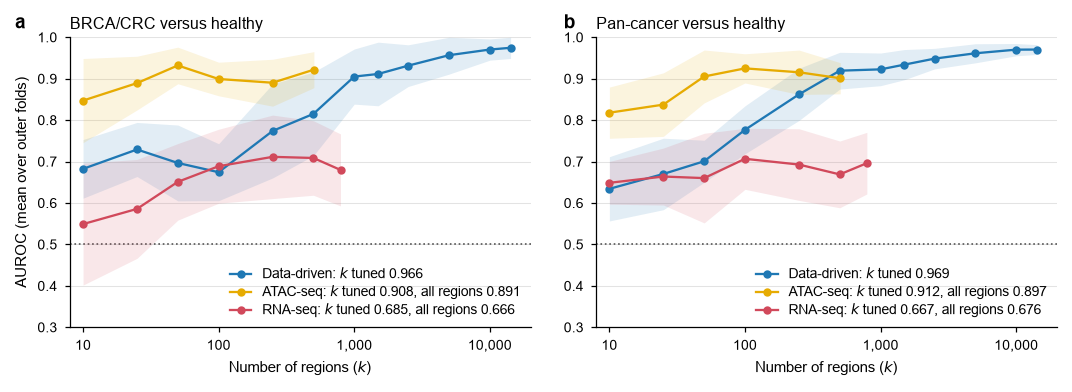

In [5]:
TASK_SHORT = {"brca_crc": "BRCA/CRC versus healthy", "pancan": "Pan-cancer versus healthy"}
# the AUROC-against-k panels, one per task side by side; shared figure style (_figstyle)
fig, axes = plt.subplots(1, len(TASKS), figsize=fs.size(height=2.5), squeeze=False, sharey=True, layout="constrained")
for i, (task, letter) in enumerate(zip(TASKS, "ab")):
    panel_auc_vs_k(axes[0][i], task)
    fs.panel(axes[0][i], letter, TASK_SHORT[task])
    if i > 0:
        axes[0][i].set_ylabel("")
        axes[0][i].tick_params(labelleft=True)   # tick labels keep the panel letter clear of the title
fs.save(fig, out_path("figS13"))
plt.show()

## Headline numbers — does tuning the number of regions change the comparison?

Per comparator: the fixed-region AUROC, the AUROC with *k* tuned inside the folds, their paired
per-fold difference, the chosen *k* values and the sweep's best point (read off the outer folds, hence
optimistic). Then the data-driven model against each comparator with the same tuning, paired over the
ten outer folds, plus sensitivity at the train-derived 95%-specificity threshold. The data-driven tuned
arm must equal the data-driven arm of Figures 3 and 4a (checked).

In [6]:
ROWS = []
for task in TASKS:
    print(f"=== {TASK_LABELS[task]} ===")
    dd_t = arm_pred(task, "data_driven", "tuned")
    dd_auc = fold_aucs(dd_t) if len(dd_t) else None
    for m in METHODS:
        fx, tu = arm_pred(task, m, "fixed"), arm_pred(task, m, "tuned")
        sw = arms[(arms["task"] == task) & (arms["method"] == m)
                  & (arms["arm"] == "ksweep")].sort_values("k")
        row = {"task": task, "method": METHOD_LABELS[m]}
        info = arms[(arms["task"] == task) & (arms["method"] == m)]
        if not len(info):
            continue                      # not exported for this task
        row["regions"] = int(info["n_regions_nominal"].iloc[0])
        row["unique_cols"] = (int(info["n_regions_total"].dropna().iloc[0])
                              if info["n_regions_total"].notna().any() else np.nan)
        if len(fx):
            a = fold_aucs(fx); s, _ = operating_point(fx)
            row.update(fixed_auc=a.mean(), fixed_sd=a.std(ddof=0), fixed_sens95=np.nanmean(s))
        if len(tu):
            a = fold_aucs(tu); s, _ = operating_point(tu)
            row.update(tuned_auc=a.mean(), tuned_sd=a.std(ddof=0), tuned_sens95=np.nanmean(s))
            ks = cfg[(cfg["task"] == task) & (cfg["method"] == m) & (cfg["arm"] == "tuned")]["k"]
            vc = ks.astype(int).value_counts().sort_index(ascending=False)
            row["k_chosen"] = "; ".join(f"{k}×{v}" for k, v in vc.items())
        if len(fx) and len(tu):
            st = paired(fold_aucs(tu), fold_aucs(fx))
            row.update(delta_tuned_minus_fixed=st["delta"], folds_improved=f"{st['wins']}/{st['n']}",
                       wilcoxon_p=st["p"])
        if len(sw):
            best = sw.loc[sw["mean_test_auc"].idxmax()]
            row.update(sweep_peak_k=int(best["k"]), sweep_peak_auc=float(best["mean_test_auc"]),
                       sweep_all_auc=float(sw["mean_test_auc"].iloc[-1]))
        if dd_auc is not None and m != "data_driven" and len(tu):
            st = paired(dd_auc, fold_aucs(tu))
            row.update(dd_minus_tuned=st["delta"], dd_wins=f"{st['wins']}/{st['n']}", dd_p=st["p"])
        ROWS.append(row)
    t = pd.DataFrame([r for r in ROWS if r["task"] == task]).drop(columns="task")
    print(t.to_string(index=False, float_format=lambda v: f"{v:.3f}"))

    # Plain-language reading per comparator.
    for m in ["rna", "atac"]:
        r = next((r for r in ROWS if r["task"] == task and r["method"] == METHOD_LABELS[m]), None)
        if r is None or "tuned_auc" not in r:
            print(f"  {METHOD_LABELS[m]}: tuned arm not available yet.")
            continue
        parts = [f"{METHOD_LABELS[m]}: k tuned per fold gives AUROC {r['tuned_auc']:.3f}"]
        if "fixed_auc" in r:
            parts.append(f"vs {r['fixed_auc']:.3f} with all {r['regions']:,} regions "
                         f"(Δ {r['delta_tuned_minus_fixed']:+.3f}, {r['folds_improved']} folds better, "
                         f"Wilcoxon p = {r['wilcoxon_p']:.2g})")
        if "dd_minus_tuned" in r:
            parts.append(f"; data-driven still ahead by {r['dd_minus_tuned']:+.3f} "
                         f"({r['dd_wins']} folds, p = {r['dd_p']:.2g})")
        print("  " + " ".join(parts))
    print()

HEADLINE = pd.DataFrame(ROWS)
HEADLINE.to_csv(out_path("figS13_headline.csv"), index=False)

# The data-driven tuned arm must equal the Figure 3 / 4a arm; checked against this cohort's own
# export only (the full-cohort fallback file is a different cohort).
for task, ref_name in [("brca_crc", "fig3_predictions.csv"), ("pancan", "fig4a_predictions.csv")]:
    ref_csv = os.path.join(_DATA, ref_name)
    if task not in TASKS or not os.path.exists(ref_csv):
        print(f"{task}: {ref_name} not exported for cohort {COHORT} - manuscript-arm identity check skipped")
        continue
    ref = pd.read_csv(ref_csv)
    ref = ref[ref["method"] == "data_driven"].set_index("sample_id")["score"]
    here = arm_pred(task, "data_driven", "tuned").set_index("sample_id")["score"]
    common = ref.index.intersection(here.index)
    ok = len(common) == len(ref) == len(here) and np.allclose(ref.loc[common], here.loc[common])
    print(f"{task}: data-driven tuned arm {'==' if ok else '!='} the Fig 3/5a data-driven scores "
          f"({len(common)} samples)")
    assert ok, f"{task}: data-driven tuned arm does not reproduce the manuscript arm"


=== Healthy vs BRCA + CRC ===
     method  regions  unique_cols  tuned_auc  tuned_sd  tuned_sens95                   k_chosen  sweep_peak_k  sweep_peak_auc  sweep_all_auc  fixed_auc  fixed_sd  fixed_sens95  delta_tuned_minus_fixed folds_improved  wilcoxon_p  dd_minus_tuned dd_wins  dd_p
Data-driven    14224        14221      0.966     0.029         0.812           15000×3; 10000×7         15000           0.975          0.975        NaN       NaN           NaN                      NaN            NaN         NaN             NaN     NaN   NaN
        RNA      792          781      0.685     0.094         0.175 792×4; 500×2; 250×3; 100×1           250           0.711          0.680      0.666     0.108         0.138                    0.019           4/10       0.625           0.281   10/10 0.002
       ATAC      504          497      0.908     0.045         0.762        504×5; 250×2; 100×3            50           0.932          0.922      0.891     0.096         0.675                    0

     method  regions  unique_cols  tuned_auc  tuned_sd  tuned_sens95           k_chosen  sweep_peak_k  sweep_peak_auc  sweep_all_auc  fixed_auc  fixed_sd  fixed_sens95  delta_tuned_minus_fixed folds_improved  wilcoxon_p  dd_minus_tuned dd_wins  dd_p
Data-driven    14224        14221      0.969     0.015         0.813   15000×5; 10000×5         15000           0.970          0.970        NaN       NaN           NaN                      NaN            NaN         NaN             NaN     NaN   NaN
        RNA      792          781      0.667     0.058         0.246 792×6; 100×3; 50×1           100           0.707          0.696      0.676     0.069         0.227                   -0.009           5/10       0.820           0.302   10/10 0.002
       ATAC      504          497      0.912     0.040         0.651 250×3; 100×6; 50×1           100           0.925          0.901      0.897     0.057         0.660                    0.015           6/10       0.492           0.058    9/10 0.004


# QC — under-the-hood diagnostics

Three checks: (1) the sweep-derived tuned arm reproduces a standalone fully nested run where one
exists (fold-level check recorded by the exporter); (2) the *k* = all point of each comparator's sweep
is close to its fixed-region arm (a large gap would indicate a data mismatch); (3) achieved test
specificity scatters around 0.95 for every arm. Also shown: the selected configuration along *k*.

In [7]:
tuned_cfg = cfg[cfg["arm"] == "tuned"]
print("tuned arm cross-checks (per fold):")
chk = (tuned_cfg.assign(k_matches_argmax=lambda d: d["k"] == d["k_argmax_ksweep"])
       .groupby(["task", "method"])
       .agg(folds=("fold", "size"),
            k_equals_sweep_argmax=("k_matches_argmax", "sum"),
            argmax_available=("k_argmax_ksweep", lambda s: int(s.notna().sum())),
            standalone_identical=("matches_standalone", lambda s: int(s.eq(True).sum())),
            standalone_checked=("matches_standalone", lambda s: int(s.notna().sum()))))
print(chk.to_string())

print("\nk = all sweep point vs the manuscript's fixed-region arm (both use all regions):")
for task in TASKS:
    for m in ["rna", "atac"]:
        sw = arms[(arms["task"] == task) & (arms["method"] == m) & (arms["arm"] == "ksweep")]
        fx = arms[(arms["task"] == task) & (arms["method"] == m) & (arms["arm"] == "fixed")]
        if len(sw) and len(fx):
            top = sw.sort_values("k").iloc[-1]
            print(f"  {task:<9} {METHOD_LABELS[m]:<5} sweep k=all {top['mean_test_auc']:.3f} "
                  f"({top['modal_classifier']}) vs fixed {fx['mean_test_auc'].iloc[0]:.3f} "
                  f"({fx['modal_classifier'].iloc[0]}): Δ {top['mean_test_auc'] - fx['mean_test_auc'].iloc[0]:+.3f}")

print("\nconfiguration drift along k (winning classifier / ranking function per k, votes over folds):")
for task in TASKS:
    for m in METHODS:
        fk = folds[(folds["task"] == task) & (folds["method"] == m)]
        if not len(fk):
            continue
        print(f"\n  {TASK_LABELS[task]} — {METHOD_LABELS[m]}")
        tab = (fk.groupby("k").agg(
            regions_used=("num_regions_used", "max"),
            inner_auc=("inner_cv_auc", "mean"), test_auc=("test_auc", "mean"),
            classifier=("classifier", lambda s: "; ".join(f"{k}={v}" for k, v in s.value_counts().items())),
            ranking=("selection_type", lambda s: "; ".join(f"{k}={v}" for k, v in s.value_counts().items())),
            feature=("feature", lambda s: "; ".join(f"{k}={v}" for k, v in s.value_counts().items())))
        )
        print(tab.to_string(float_format=lambda v: f"{v:.3f}"))

print("\nachieved test specificity at the train-derived threshold, mean over folds (≈ 0.95):")
rows = []
for (task, m, arm), g in pred[pred["arm"] != "ksweep"].groupby(["task", "method", "arm"]):
    _, spec = operating_point(g)
    sens, _ = operating_point(g)
    rows.append({"task": task, "method": METHOD_LABELS[m], "arm": arm,
                 "sens@95": np.nanmean(sens), "achieved spec": np.nanmean(spec)})
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.3f}"))

print("\npooled OOF AUROC (rank-normalised within fold) with bootstrap 95% CI, tuned arms:")
for task in TASKS:
    for m in METHODS:
        df = arm_pred(task, m, "tuned")
        if len(df):
            a, lo, hi = pooled_auc_ci(df)
            print(f"  {task:<9} {METHOD_LABELS[m]:<12} {a:.3f} [{lo:.3f}, {hi:.3f}]")


tuned arm cross-checks (per fold):
                      folds  k_equals_sweep_argmax  argmax_available  standalone_identical  standalone_checked
task     method                                                                                               
brca_crc atac            10                     10                10                     0                   0
         data_driven     10                     10                10                     0                   0
         rna             10                     10                10                     0                   0
pancan   atac            10                     10                10                     0                   0
         data_driven     10                     10                10                     0                   0
         rna             10                     10                10                     0                   0

k = all sweep point vs the manuscript's fixed-region arm (both use all regio

  brca_crc  Data-driven  0.966 [0.943, 0.984]


  brca_crc  RNA          0.684 [0.618, 0.751]


  brca_crc  ATAC         0.908 [0.862, 0.949]


  pancan    Data-driven  0.969 [0.954, 0.982]


  pancan    RNA          0.667 [0.611, 0.720]


  pancan    ATAC         0.911 [0.882, 0.939]
